# Recitation: Logistic Regression

**Today we will learn:**
1. What is classification?
2. How does logistic regression work?
3. How do we train and test a model?
4. How do we check its predictions?

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

## 1. Classification vs. Regression

- **Regression:** Predict a number, like a house price.
- **Classification:** Predict a group, like spam or not spam.

**Logistic regression is a classification model.** It predicts the chance of a class.

## 2. How Logistic Regression Works

First, the model combines the input features into a score:

$$z = w_0 + w_1x_1 + \cdots + w_px_p$$

Then the **sigmoid function** changes the score into a probability:

$$P(y=1) = \frac{1}{1+e^{-z}}$$

- The probability is between **0 and 1**.
- If the probability is **0.5 or more**, predict class **1**.
- Otherwise, predict class **0**.

This 0.5 cutoff is called the **decision threshold**.

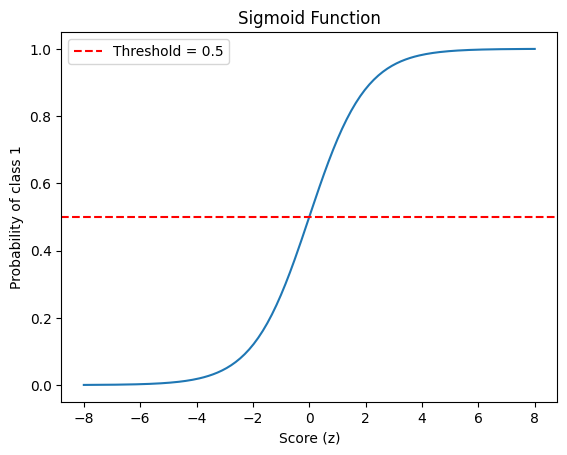

In [6]:
# The sigmoid curve
z = np.linspace(-8, 8, 200)
p = 1 / (1 + np.exp(-z))


plt.plot(z, p)
plt.axhline(0.5, color='red', linestyle='--', label='Threshold = 0.5')
plt.xlabel('Score (z)')
plt.ylabel('Probability of class 1')
plt.title('Sigmoid Function')
plt.legend()
plt.show()

## 3. Train a Model with Real Data

We will use a breast cancer dataset.

- **569 samples**, **30 features**
- **0 = Malignant** (cancerous)
- **1 = Benign** (not cancerous)

Our goal is to predict the class from the features.

In [7]:
# Load data
cancer = load_breast_cancer()
X, y = cancer.data, cancer.target

# Split: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train and predict
model = LogisticRegression(max_iter=5000, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

print('First 5 predicted classes:', y_pred[:5])
print('First 5 probabilities of benign(not cancerous):', y_prob[:5, 1].round(2))

First 5 predicted classes: [0 1 0 1 0]
First 5 probabilities of benign(not cancerous): [0.   1.   0.01 0.53 0.  ]


/Users/wenyi/miniconda3/envs/test/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/wenyi/miniconda3/envs/test/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/wenyi/miniconda3/envs/test/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/wenyi/miniconda3/envs/test/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/wenyi/miniconda3/envs/test/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X

## 4. How Good Is Our Model?

**Accuracy** = number of correct predictions / total predictions.

But accuracy does not tell us *which mistakes* the model makes.

A **confusion matrix** shows the actual classes and predicted classes.

- **Precision:** Of the cases predicted as one class, how many are correct?
- **Recall:** Of the actual cases in that class, how many did we find?
- **F1-score:** A combined score for precision and recall.


Accuracy: 98.2%


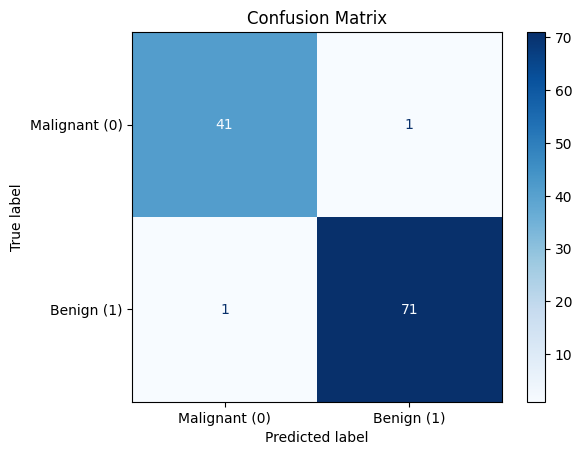

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [8]:
print(f'Accuracy: {accuracy_score(y_test, y_pred):.1%}')

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['Malignant (0)', 'Benign (1)'], cmap='Blues'
)
plt.title('Confusion Matrix')
plt.show()

print(classification_report(y_test, y_pred, target_names=['Malignant', 'Benign']))

## 5. Key Takeaways

1. **Classification** predicts classes, not numbers.
2. **Logistic regression** uses sigmoid to predict probabilities.
3. A **threshold** turns a probability into a class.
4. We **split** data and **scale** features before training.
5. Check **accuracy, confusion matrix, precision, recall, and F1**.

**Quick questions:**
- What does sigmoid do?
- What does `predict_proba()` return?
- Why is accuracy not always enough?

**Answers:**

1\. What does sigmoid do?\
Sigmoid converts any real number into a value between 0 and 1, which can be interpreted as a probability.

2\. What does `predict_proba()` return?\
It returns the predicted probabilities for each class. For binary classification, it typically returns `[P(class 0), P(class 1)]` for each sample.

3\. Why is accuracy not always enough?\
Accuracy can be misleading on imbalanced datasets. For example, if 95% of samples belong to one class, always predicting that class gives 95% accuracy. Metrics like precision, recall, and F1-score provide a more complete evaluation.